In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.constants import c
import miepython

plt.style.use('style.mplstyle')  # was '/Users/alexg/Python Projects/alex_style.mplstyle' (Mac)

In [2]:
def Ray(f, d, n_p, n_m, N=1/u.m**3, h=0.0254*u.m):
    G = np.pi/4*d**2 # geometric cross section of the particle

    x = (np.pi*n_m*d*f/c).to(1).value # size parameter x = pi*n_m*d/lambda (wavelength in the matrix)
    m = n_p/n_m # particle/inclusion index over matrix index
    Q = 8/3 * x**4 * ((m**2-1)/(m**2+2))**2   # Clausius-Mossotti factor uses m^2

    return Q, np.exp(-N*G*Q*h)

def RGD(f, d, n_p, n_m, N=1/u.m**3, h=0.0254*u.m):
    G = np.pi/4*d**2 # geometric cross section of the particle

    x = (np.pi*n_m*d*f/c).to(1).value # size parameter x = pi*n_m*d/lambda (wavelength in the matrix)
    m = n_p/n_m # particle/inclusion index over matrix index
    Q = 2*x**2*(m-1)**2

    return Q, np.exp(-N*G*Q*h)

def vdH(f, d, n_p, n_m, N=1/u.m**3, h=0.0254*u.m):
    G = np.pi/4*d**2 # geometric cross section of the particle
    
    x = (np.pi*n_m*d*f/c).to(1).value # size parameter x = pi*n_m*d/lambda (wavelength in the matrix)
    m = n_p/n_m # particle/inclusion index over matrix index 
    # print(m)
    rho = 2*x*(m-1)
    # print(rho)

    Q = 2 - 4*np.sin(rho)/rho + 4*(1-np.cos(rho))/rho**2

    return Q, np.exp(-N*G*Q*h)

def vdH_loss(f, d, n_p, n_m, beta, N=1/u.m**3, h=0.0254*u.m):
    G = np.pi/4*d**2 # geometric cross section of the particle

    x = (np.pi*n_m*d*f/c).to(1).value # size parameter x = pi*n_m*d/lambda (wavelength in the matrix)
    m = n_p/n_m # particle/inclusion index over matrix index 
    rho = 2*x*(m-1)
    
    Q = 2 - 4*np.exp(-rho*np.tan(beta))*np.cos(beta)/rho*np.sin(rho-beta) - 4*np.exp(-rho*np.tan(beta))*(np.cos(beta)/rho)**2*np.cos(rho-2*beta) + 4*(np.cos(beta)/rho)**2*np.cos(2*beta)

    return Q, np.exp(-N*G*Q*h)

def fra(d, N=1/u.m**3, h=0.0254*u.m):
    G = np.pi/4*d**2 # geometric cross section of the particle
    Q = 2

    return Q, np.exp(-N*G*Q*h)

from scipy.special import j0, j1

def Q_geo(f, K_geo):
    """Geometric-optics extinction seen by a detector with acceptance half-angle theta_a.
    Extinction = 1 (blocking) + the diffracted fraction outside the acceptance cone; the diffracted
    light is an Airy pattern whose power inside theta_a is 1 - J0^2(u) - J1^2(u) (Rayleigh's encircled
    energy), with u = pi d sin(theta_a) / lambda = f / K_geo. Falls smoothly from 2 to 1.
    K_geo = c / (pi d sin theta_a), so only the product d sin(theta_a) is set by K_geo."""
    u_ = (f / K_geo).to(1).value
    return 1 + j0(u_)**2 + j1(u_)**2

def Mie(f, d, n_p, n_m, N=1/u.m**3, h=0.0254*u.m):
    """Exact Lorenz-Mie scattering efficiency of a homogeneous sphere (index n_p) in a matrix (index n_m), from miepython.
    Same x and m as the approximations above, so it reduces to Rayleigh (x << 1) and to van de Hulst (|m - 1| << 1, x >> 1)."""
    G = np.pi/4*d**2 # geometric cross section of the particle

    x = (np.pi*n_m*d*f/c).to(1).value # size parameter x = pi*n_m*d/lambda (wavelength in the matrix)
    m = n_p/n_m # particle/inclusion index over matrix index
    Q = miepython.efficiencies_mx(m, x)[1]   # Q_sca

    return Q, np.exp(-N*G*Q*h)

from fullmie_funcs import LX, shell_table, wall_factor

def thin_shell(f, d, n_p, f_p, s=0, N=1/u.m**3, h=0.0254*u.m):
    """Full Mie for a closed foam cell, the model of main.ipynb (fullmie_funcs.py): a thin polymer shell of index n_p with
    air inside and outside (Lange & Aragon 1990, first order in the wall thickness). Q_sca = (2 l/d)^2 G(x), x = pi d f/c
    (wavelength in air), with walls l = c_l d holding the polymer volume fraction f_p, c_l = (1 - (1 - f_p)^(1/3))/2.
    s > 0: log-normal number distribution ln d ~ N(ln d, s^2); Q is then the cross-section-weighted average and G the
    mean cross section."""
    G = np.pi/4*d**2*np.exp(2*s**2) # mean geometric cross section of the cells
    cl = wall_factor(1 - f_p)
    lnG = np.log(shell_table(n_p))  # ln G on the ln x grid LX (cached in pkls/)

    def Q_one(x):
        lx = np.log(x)
        return (2*cl)**2*np.exp(np.where(lx < LX[0], lnG[0] + 4*(lx - LX[0]), np.interp(lx, LX, lnG)))  # x^4 below the table

    x = (np.pi*d*f/c).to(1).value
    if s == 0:
        Q = Q_one(x)
    else:
        z = np.linspace(-4, 4 + 4*s, 201) # the area weighting shifts the median to d e^{2 s^2}
        w = np.exp(-z**2/2)
        Q = np.sum(w*Q_one(np.multiply.outer(x, np.exp(2*s**2 + s*z))), axis=-1)/np.sum(w)

    return Q, np.exp(-N*G*Q*h)


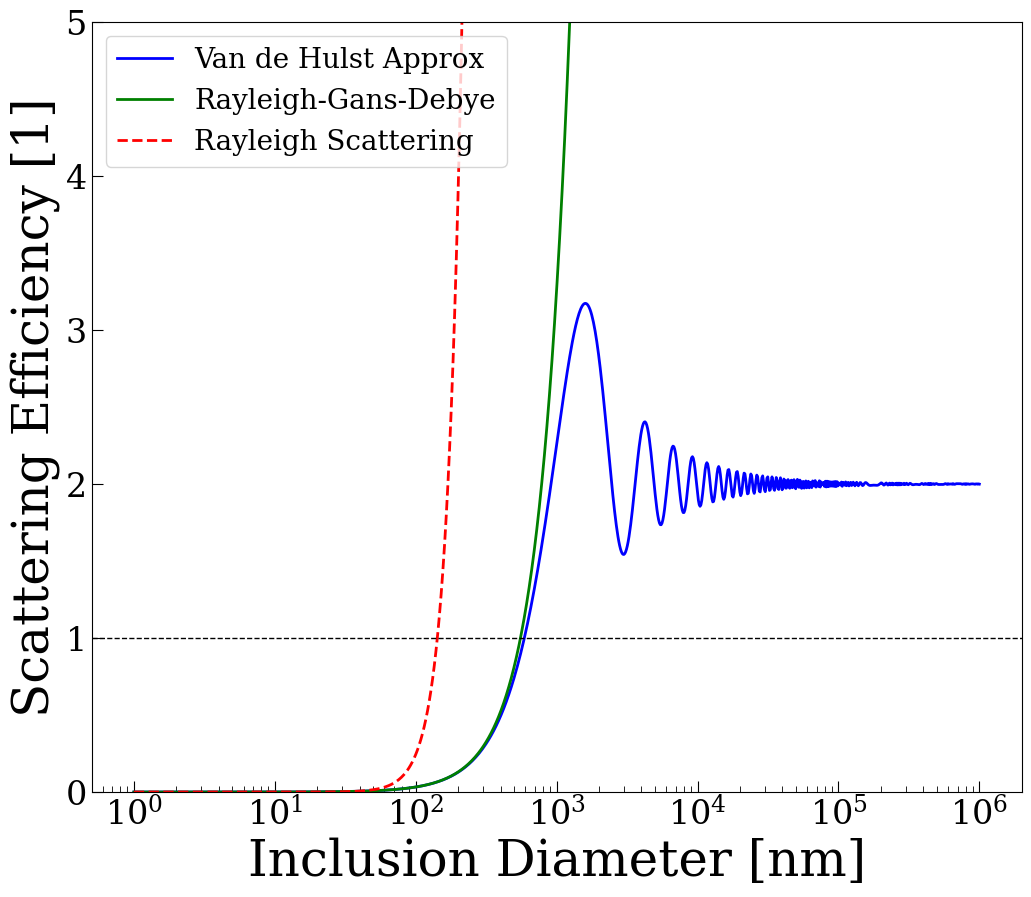

In [3]:
lamb = 155*u.nm # wavelength in meters
f = c/lamb
inclusion_diameter = np.logspace(-9, -3, 1000)*u.m

Q_vdH = vdH(f, inclusion_diameter, 1.826, 1.763)[0]
Q_RGD = RGD(f, inclusion_diameter, 1.826, 1.763)[0]
Q_ray = Ray(f, inclusion_diameter, 1.826, 1.763)[0]

plt.figure(figsize=(12, 10))
plt.plot(inclusion_diameter*1e9, Q_vdH, color='b', label='Van de Hulst Approx',  lw=2)
plt.plot(inclusion_diameter*1e9, Q_RGD, 'g-', label='Rayleigh-Gans-Debye', lw=2)
plt.plot(inclusion_diameter*1e9, Q_ray, 'r--', label='Rayleigh Scattering', lw=2)
plt.axhline(1, color='k', lw=1, ls='--')
plt.legend(loc='upper left')
plt.ylim(0, 5)
plt.xlabel('Inclusion Diameter [nm]')
plt.ylabel('Scattering Efficiency [1]')
plt.xscale('log')
plt.gcf().set_facecolor('white')
plt.show()

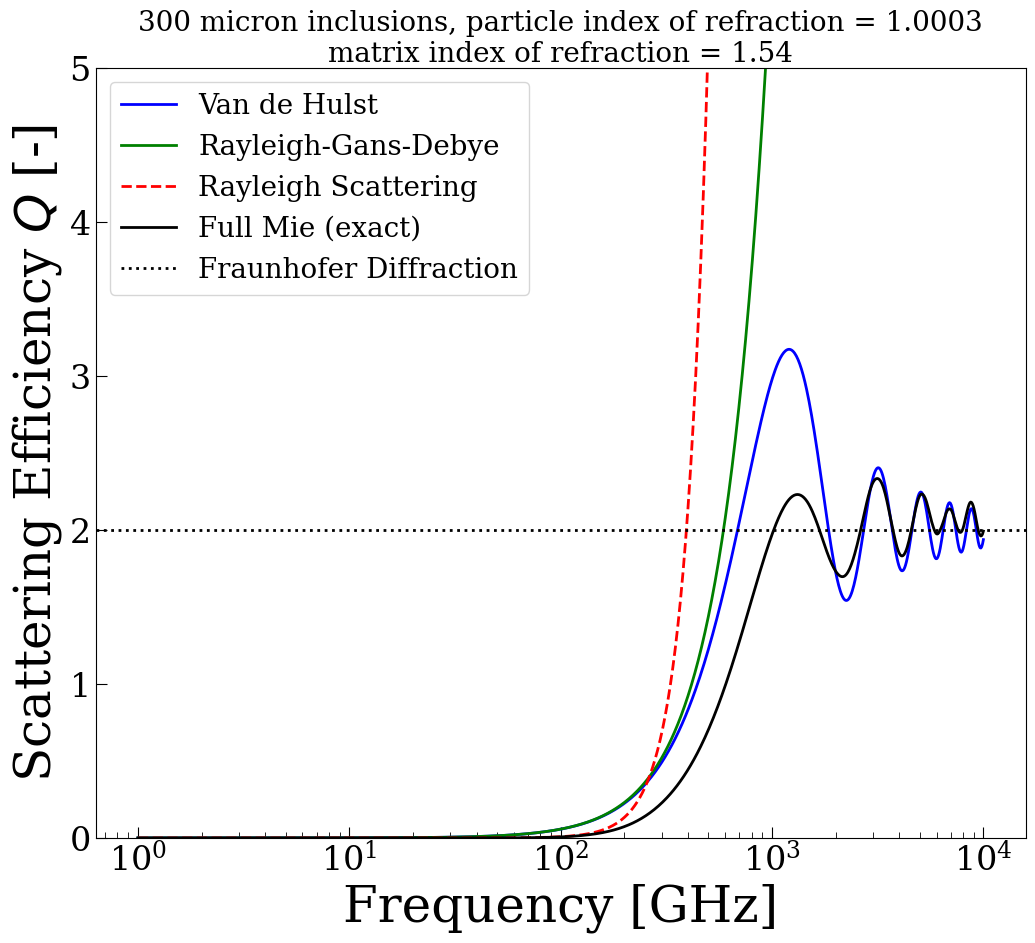

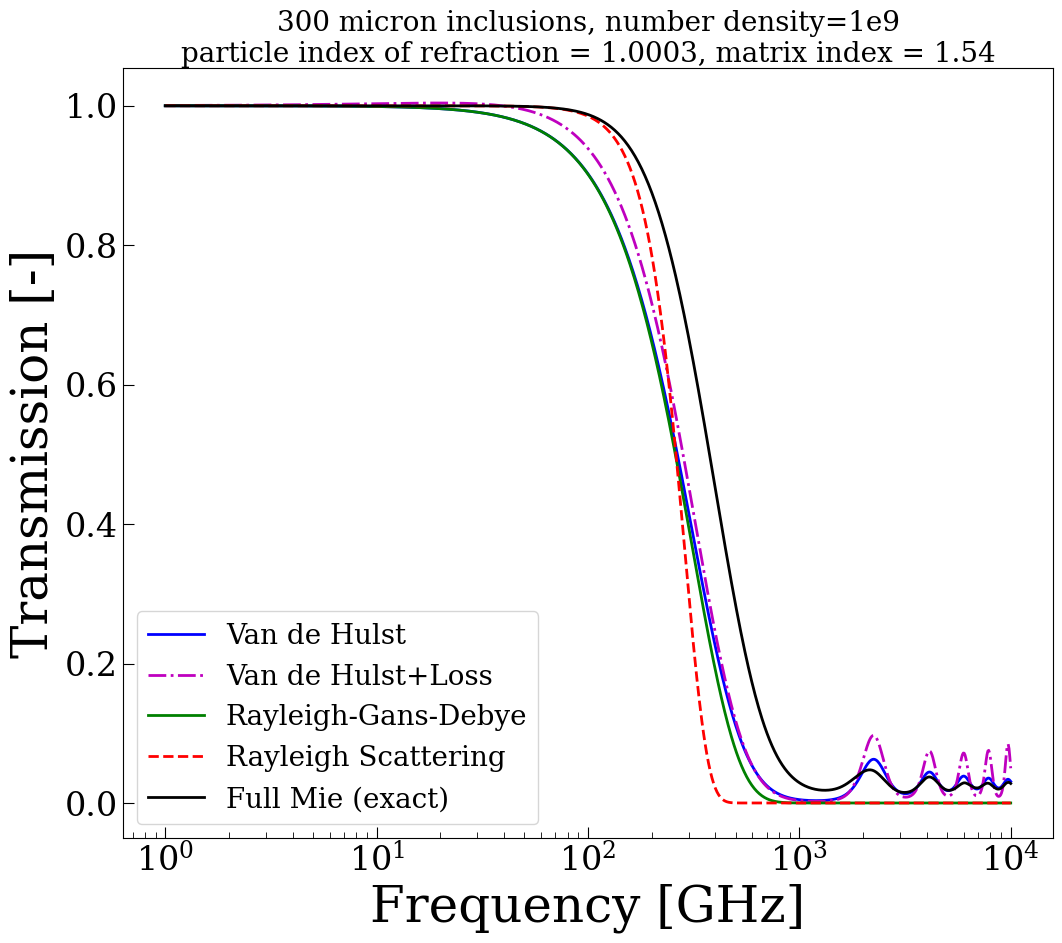

In [18]:
f = np.logspace(0, 4, 1000)*u.GHz
d = 300*u.um
n_p = 1.0003
n_m = 1.54

# print(f.to(u.GHz))
Q_vdH, T_vdH = vdH(f, d, n_p, n_m, N=1e9/u.m**3)
Q_RGD, T_RGD = RGD(f, d, n_p, n_m, N=1e9/u.m**3)
Q_ray, T_ray = Ray(f, d, n_p, n_m, N=1e9/u.m**3)
Q_mie, T_mie = Mie(f, d, n_p, n_m, N=1e9/u.m**3)
Q_vdH_loss, T_vdH_loss = vdH_loss(f, d, n_p, n_m, 5e-2, N=1e9/u.m**3)
T_fra = fra(d, N=1e9/u.m**3)[1]

# print(f[np.argmin(np.abs(Q_vdH-1))]/1e9, f[np.argmin(np.abs(Q_RGD-1))]/1e9, f[np.argmin(np.abs(Q_ray-1))]/1e9)

plt.figure(figsize=(12, 10))
# plt.title('Scattering Efficiency vs Frequency', y=1.08)
plt.text(0.5, 1, '300 micron inclusions, particle index of refraction = 1.0003\nmatrix index of refraction = 1.54', ha='center', va='bottom', fontsize=20, transform=plt.gca().transAxes)

plt.plot(f, Q_vdH, color='b', label='Van de Hulst',  lw=2)
plt.plot(f, Q_RGD, 'g-', label='Rayleigh-Gans-Debye', lw=2)
plt.plot(f, Q_ray, 'r--', label='Rayleigh Scattering', lw=2)
plt.plot(f, Q_mie, 'k-', label='Full Mie (exact)', lw=2)
plt.axhline(2, color='k', ls=':', label='Fraunhofer Diffraction', lw=2)
# plt.axhline(1, color='k', lw=1, ls='--')
plt.legend(loc='upper left', fontsize=20)
plt.ylim(0, 5)
plt.xlabel('Frequency [GHz]')
plt.ylabel('Scattering Efficiency $Q$ [-]')
plt.xscale('log')
plt.gcf().set_facecolor('none')
plt.show()

plt.figure(figsize=(12, 10))

plt.text(0.5, 1, '300 micron inclusions, number density=1e9\nparticle index of refraction = 1.0003, matrix index = 1.54', ha='center', va='bottom', fontsize=20, transform=plt.gca().transAxes)
plt.plot(f, T_vdH, color='b', label='Van de Hulst',  lw=2)
plt.plot(f, T_vdH_loss, 'm-.', label='Van de Hulst+Loss', lw=2)
plt.plot(f, T_RGD, 'g-', label='Rayleigh-Gans-Debye', lw=2)
plt.plot(f, T_ray, 'r--', label='Rayleigh Scattering', lw=2)
plt.plot(f, T_mie, 'k-', label='Full Mie (exact)', lw=2)
plt.legend(loc='lower left', fontsize=20)
# plt.ylim(0.9, 1)
plt.xlabel('Frequency [GHz]')
plt.ylabel('Transmission [-]')
plt.xscale('log')
plt.gcf().set_facecolor('none')
plt.show()

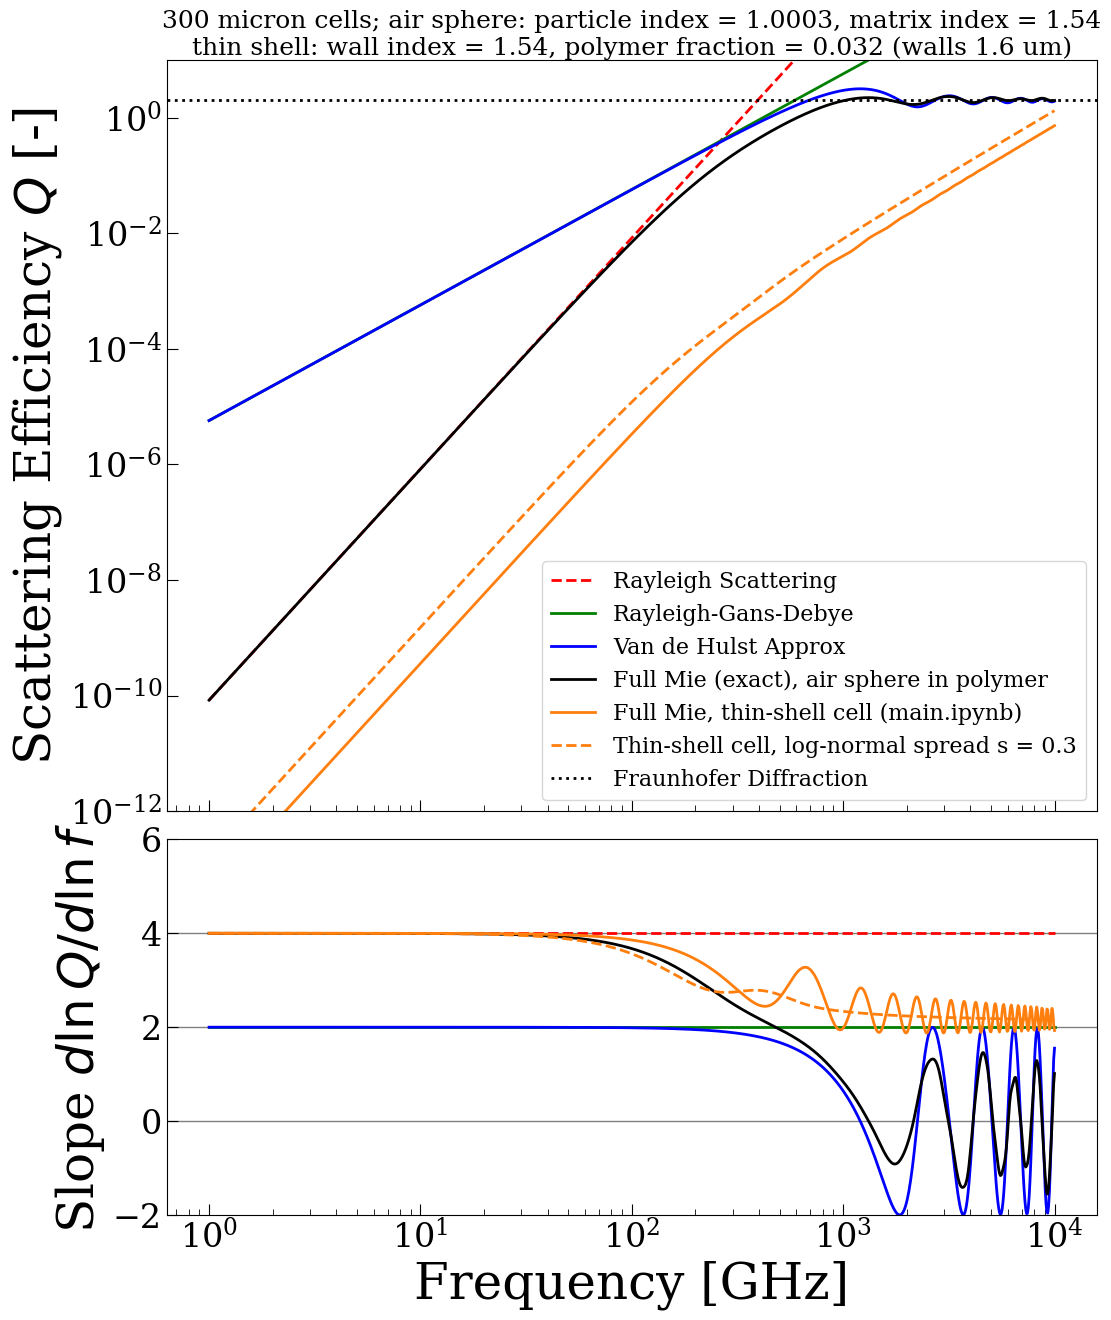

In [5]:
## Log-log view of the efficiencies above, with the slope d ln Q / d ln f below, so the power laws can be read off.
## Added: the thin-shell full Mie of main.ipynb for the same 300 um cells (polymer walls of index n_m in air,
## HD30's polymer fraction), as one size and with a log-normal spread s = 0.3 (the size of the fitted spreads).
## Note the geometries differ: the solid curves are an air sphere embedded in polymer, the thin shells are a foam cell.
f_p = 30/950 # HD30 density / polyethylene density
Q_shell,   _ = thin_shell(f, d, n_m, f_p)
Q_shell_s, _ = thin_shell(f, d, n_m, f_p, s=0.3)

curves = [(Q_ray,     'Rayleigh Scattering',                       dict(color='r', ls='--')),
          (Q_RGD,     'Rayleigh-Gans-Debye',                       dict(color='g', ls='-')),
          (Q_vdH,     'Van de Hulst Approx',                       dict(color='b', ls='-')),
          (Q_mie,     'Full Mie (exact), air sphere in polymer',   dict(color='k', ls='-')),
          (Q_shell,   'Full Mie, thin-shell cell (main.ipynb)',    dict(color='tab:orange', ls='-')),
          (Q_shell_s, 'Thin-shell cell, log-normal spread s = 0.3', dict(color='tab:orange', ls='--'))]

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(12, 15), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
ax0.text(0.5, 1, '300 micron cells; air sphere: particle index = 1.0003, matrix index = 1.54\n'
         f'thin shell: wall index = 1.54, polymer fraction = {f_p:.3f} (walls {1e3*wall_factor(1 - f_p)*d.to(u.mm).value:.1f} um)',
         ha='center', va='bottom', fontsize=18, transform=ax0.transAxes)
for Q, label, kw in curves:
    ax0.plot(f, Q, label=label, lw=2, **kw)
    ax1.plot(f, np.gradient(np.log(Q), np.log(f.value)), lw=2, **kw)
ax0.axhline(2, color='k', ls=':', label='Fraunhofer Diffraction', lw=2)
for k in (4, 2, 0):
    ax1.axhline(k, color='gray', lw=1, zorder=0)
ax0.set(xscale='log', yscale='log', ylim=(1e-12, 1e1), ylabel='Scattering Efficiency $Q$ [-]')
ax1.set(ylim=(-2, 6), yticks=[-2, 0, 2, 4, 6], xlabel='Frequency [GHz]', ylabel=r'Slope $d\ln Q/d\ln f$')
ax0.legend(loc='lower right', fontsize=16)
fig.subplots_adjust(hspace=0.05)
fig.set_facecolor('white')
plt.show()


Volume density ~ 4.5e+10 cells/m3


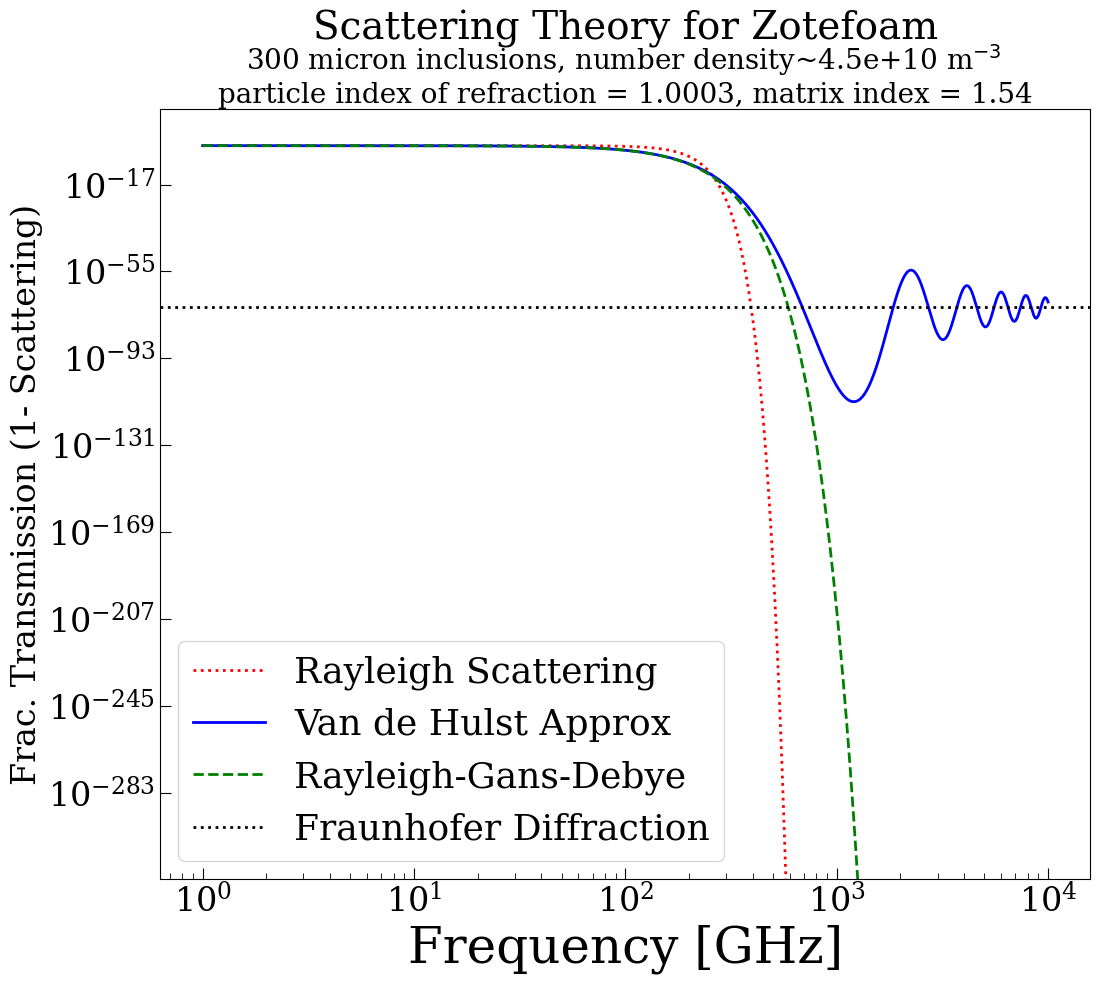

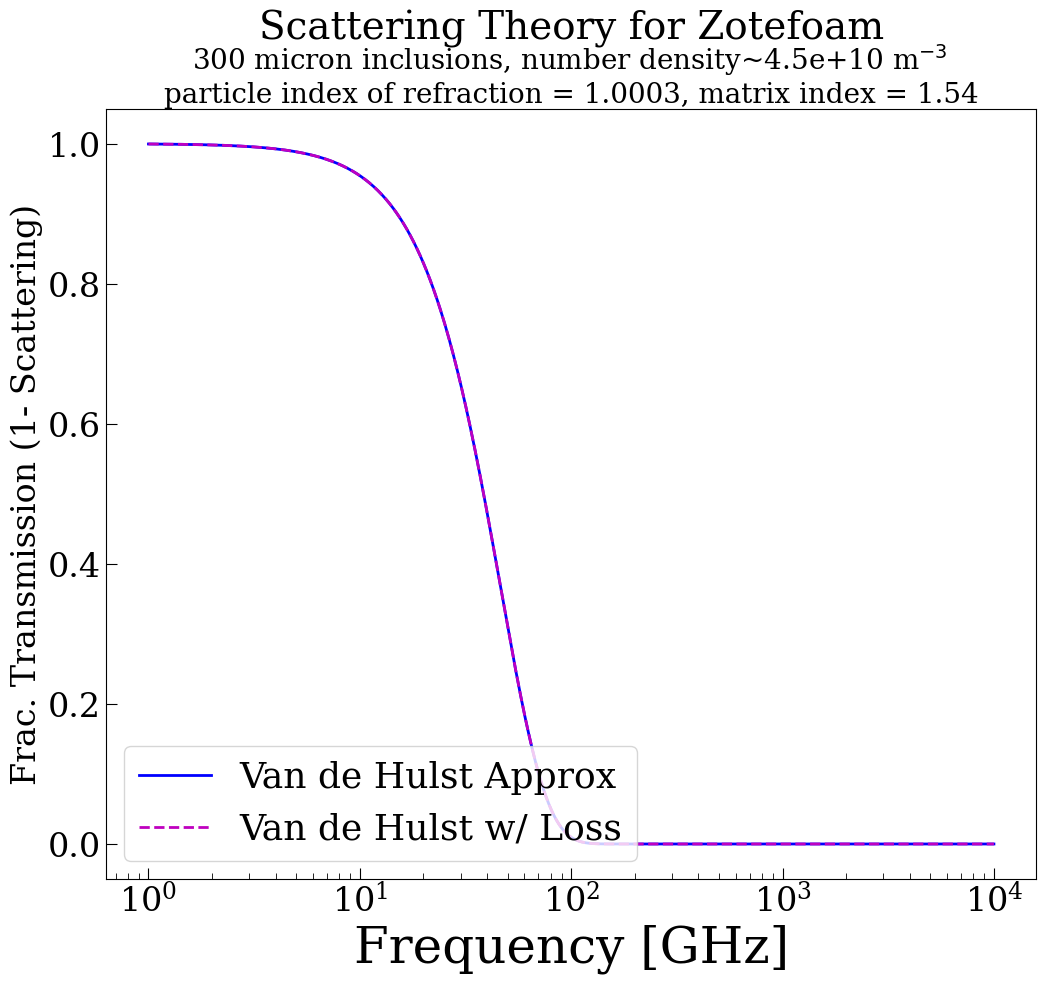

In [15]:
V = 4/3*np.pi*(d/2)**3
N = (0.64/V).to(1/u.m**3)
print(f"Volume density ~ {N.value:.2g} cells/m3")

Q_vdH, T_vdH = vdH(f, d, n_p, n_m, N)
Q_RGD, T_RGD = RGD(f, d, n_p, n_m, N)
Q_ray, T_ray = Ray(f, d, n_p, n_m, N)
Q_vdH_loss, T_vdH_loss = vdH_loss(f, d, n_p, n_m, 5e-6, N)
T_fra = fra(d, N)[1]

plt.figure(figsize=(12, 10))
plt.title('Scattering Theory for Zotefoam', y=1.08)

plt.text(0.5, 1, f'300 micron inclusions, number density~{N.value:.2g} m$^{{-3}}$ \nparticle index of refraction = 1.0003, matrix index = 1.54', ha='center', va='bottom', fontsize=20, transform=plt.gca().transAxes)
plt.plot(f, T_ray, 'r:', label='Rayleigh Scattering', lw=2)
plt.plot(f, T_vdH, color='b', label='Van de Hulst Approx',  lw=2)
plt.plot(f, T_RGD, 'g--', label='Rayleigh-Gans-Debye', lw=2)

plt.axhline(T_fra, color='k', ls=':', lw=2, label='Fraunhofer Diffraction')
plt.legend(loc='lower left', fontsize=26)
# plt.ylim(0.9, 1)
plt.xlabel('Frequency [GHz]')
# plt.ylabel('Transmission [= exp($-Q\sigma Nw$)]')
plt.ylabel('Frac. Transmission (1- Scattering)', fontsize=24)
plt.xscale('log')
plt.yscale('log')
plt.gcf().set_facecolor('none')
plt.show()

plt.figure(figsize=(12, 10))
plt.title('Scattering Theory for Zotefoam', y=1.08)

plt.text(0.5, 1, f'300 micron inclusions, number density~{N.value:.2g} m$^{{-3}}$ \nparticle index of refraction = 1.0003, matrix index = 1.54', ha='center', va='bottom', fontsize=20, transform=plt.gca().transAxes)
plt.plot(f, T_vdH, color='b', label='Van de Hulst Approx',  lw=2)
plt.plot(f, T_vdH_loss, 'm--', label='Van de Hulst w/ Loss', lw=2)

plt.legend(loc='lower left', fontsize=26)
# plt.ylim(0.9, 1)
plt.xlabel('Frequency [GHz]')
# plt.ylabel('Transmission [= exp($-Q\sigma Nw$)]')
plt.ylabel('Frac. Transmission (1- Scattering)', fontsize=24)
plt.xscale('log')
# plt.yscale('log')
plt.gcf().set_facecolor('none')
plt.show()

In [7]:
vdH(150*u.GHz, d, n_p, n_m, N)

(np.float64(0.1276916650692579), <Quantity 3.10852062e-05>)

for scattering efficiency $Q$, cross section $\sigma$, Number density $N$, and material width $w$.

Converting our parameters to values with physical interpretations,

$$
K_{\textrm{ray}} = \frac{\pi n_m}{c}\left(\frac{64d^3}{25}\right)^{1/4}\left|\frac{m^2-1}{m^2+2}\right|^{1/2}
$$

Conversely, 
$$
d = \left(\frac{25}{64}\right)^{1/3}\left(\frac{K_{\textrm{ray}} c}{\pi n_m}\right)^{4/3}\left|\frac{m^2+2}{m^2-1}\right|^{2/3}
$$

In [8]:
def d_to_Kray(d, n_p, n_m, N=1/u.m**3):
    G = np.pi/4*d**2 # geometric cross section of the particle

    x = (np.pi*n_m*d/c).to(1/u.GHz) #f is removed since it cancels out
    m = n_p/n_m # particle/inclusion index over matrix index
    Q = 8/3 * x**4 * ((m**2-1)/(m**2+2))**2

    K_ray = ((N*G*Q)**(1/4)).to(1/u.GHz/u.m**(1/4))
    # K_ray = (np.pi*n_m/c*(64*d**3/25)**(1/4)*np.abs((m**2-1)/(m**2+2))**(1/2))
    return K_ray

def Kray_to_d(K_ray, n_p, n_m, N=1/u.m**3):
    m = n_p/n_m
    d = ((25/64)**(1/3)*(K_ray*c/np.pi/n_m)**(4/3)*np.abs((m**2+2)/(m**2-1))**(2/3)).to(u.um)
    return d

In [9]:
n_p = 1.014
n_m = 1.54
m = n_p/n_m # particle/inclusion index over matrix index


Kray_est = d_to_Kray(300*u.um, n_p, n_m, N)
print(Kray_est)

print(Kray_to_d(Kray_est, n_p, n_m))

## Assume that 64% of the space is filled, so 86% of each dimension is fille.
# N ~ 0.86/d

K_ray = (np.pi*n_m/c*(64*d**3/25)**(1/4)*np.abs((m**2-1)/(m**2+2))**(1/2))
K_ray = K_ray.to(1/u.GHz/u.m**(1/4))
print(K_ray)

K_ray = 2.65203555e-03/u.GHz/u.m**(1/4)
d_ray = Kray_to_d(K_ray, n_p, n_m)
print(d_ray)

0.02244986348486308 1 / (m(1/4) GHz)
300.0000000000001 um
0.02244986348486308 1 / (m(1/4) GHz)
17.389033226608294 um
